<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/06_%E5%84%AA%E5%8C%96%E7%AE%97%E6%B3%95/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. 優化算法 (Optimization: Gradient Descent)

**梯度下降 (Gradient Descent)** 是模型尋求最低損失的指南針：
$$w_{new} = w_{old} - \eta \cdot \frac{\partial L}{\partial w}$$
其中 $\eta$ 為**學習率 (Learning Rate)**。

本範例透過二次損失函數 $L(w) = w^2$（導數為 $2w$），模擬並使用 Matplotlib 繪製三種不同學習率下的參數收斂軌跡。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def gradient_descent(start_w, lr, steps=10):
    w_history = [start_w]
    w = start_w
    for _ in range(steps):
        grad = 2 * w
        w = w - lr * grad
        w_history.append(w)
    return w_history

start_w = 4.0
steps = 8

w_good = gradient_descent(start_w, lr=0.15, steps=steps)  # 適中
w_small = gradient_descent(start_w, lr=0.02, steps=steps) # 太小
w_large = gradient_descent(start_w, lr=1.05, steps=steps) # 太大 (震盪發散)

df_gd = pd.DataFrame({
    '迭代步數': list(range(steps + 1)),
    '適中步長 (lr=0.15)': np.round(w_good, 4),
    '過小步長 (lr=0.02)': np.round(w_small, 4),
    '過大步長 (lr=1.05)': np.round(w_large, 4)
})

print("=== 梯度下降更新歷程 ===")
print(df_gd)


=== 梯度下降更新歷程 ===
   迭代步數  適中步長 (lr=0.15)  過小步長 (lr=0.02)  過大步長 (lr=1.05)
0     0          4.0000          4.0000          4.0000
1     1          2.8000          3.8400         -4.4000
2     2          1.9600          3.6864          4.8400
3     3          1.3720          3.5389         -5.3240
4     4          0.9604          3.3974          5.8564
5     5          0.6723          3.2615         -6.4420
6     6          0.4706          3.1310          7.0862
7     7          0.3294          3.0058         -7.7949
8     8          0.2306          2.8856          8.5744


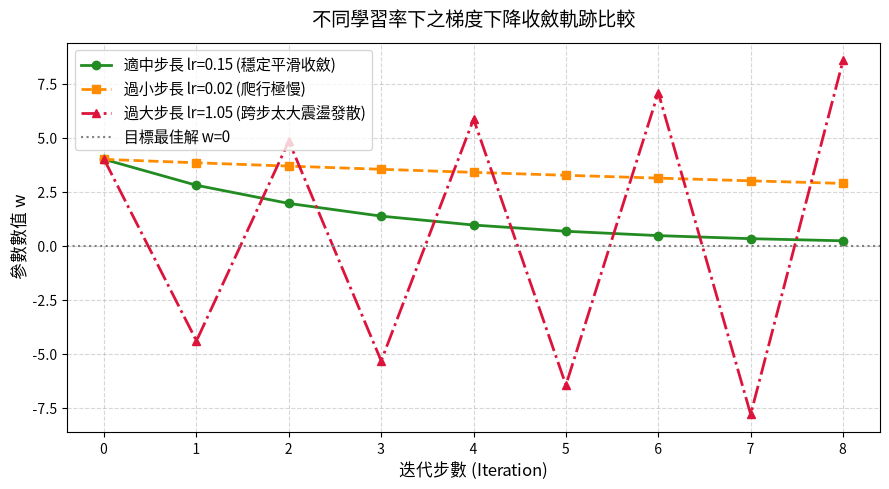

💡 觀念總結：學習率如同濃霧下山的步伐大小，步子過碎走不到底，步子過大則會墜入深谷震盪發散！


In [4]:
# 繪製收斂軌跡折線圖
plt.figure(figsize=(9, 5))
plt.plot(w_good, 'o-', color='forestgreen', linewidth=2, label='適中步長 lr=0.15 (穩定平滑收斂)')
plt.plot(w_small, 's--', color='darkorange', linewidth=2, label='過小步長 lr=0.02 (爬行極慢)')
plt.plot(w_large, '^-.', color='crimson', linewidth=2, label='過大步長 lr=1.05 (跨步太大震盪發散)')
plt.axhline(0, color='gray', linestyle=':', label='目標最佳解 w=0')

plt.title('不同學習率下之梯度下降收斂軌跡比較', fontsize=14, pad=12)
plt.xlabel('迭代步數 (Iteration)', fontsize=12)
plt.ylabel('參數數值 w', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("💡 觀念總結：學習率如同濃霧下山的步伐大小，步子過碎走不到底，步子過大則會墜入深谷震盪發散！")
